In [45]:
import numpy as np 
import pandas as pd 


In [46]:
df=pd.read_csv('kmeans_customer_segmentation_practice.csv')
cdf=df.copy()

In [47]:
cdf.head()

,Age,Annual_Income_Index,Spending_Score,Monthly_Visits,Segment_Reference
0,48.5,60.1,65.5,68.8,Regular
1,21.4,26.8,25.7,29.0,Budget
2,70.0,87.3,88.5,84.5,Premium
3,52.1,60.3,58.1,73.8,Regular
4,55.3,61.0,60.8,68.5,Regular


In [48]:
cdf.shape

(150, 5)

In [49]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  150 non-null    float64
 1   Annual_Income_Index  150 non-null    float64
 2   Spending_Score       150 non-null    float64
 3   Monthly_Visits       150 non-null    float64
 4   Segment_Reference    150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [50]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  150 non-null    float64
 1   Annual_Income_Index  150 non-null    float64
 2   Spending_Score       150 non-null    float64
 3   Monthly_Visits       150 non-null    float64
 4   Segment_Reference    150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [51]:
cdf.isna().sum()

Age                    0
Annual_Income_Index    0
Spending_Score         0
Monthly_Visits         0
Segment_Reference      0
dtype: int64

In [52]:
cdf.duplicated().sum()

np.int64(0)

In [53]:
cdf.describe()

,Age,Annual_Income_Index,Spending_Score,Monthly_Visits
count,150.000000,150.000000,150.000000,150.000000
mean,49.908667,58.188000,53.890000,62.714667
std,19.491836,26.894676,27.783834,25.655057
min,18.000000,11.900000,10.400000,23.900000
25%,26.425000,28.350000,22.675000,32.525000
50%,55.800000,60.200000,55.000000,65.500000
75%,70.000000,85.675000,83.700000,90.200000
max,70.000000,100.000000,97.500000,100.000000


In [54]:
cdf.corr(numeric_only=True)

,Age,Annual_Income_Index,Spending_Score,Monthly_Visits
Age,1.000000,0.961465,0.956000,0.966865
Annual_Income_Index,0.961465,1.000000,0.968024,0.970299
Spending_Score,0.956000,0.968024,1.000000,0.976277
Monthly_Visits,0.966865,0.970299,0.976277,1.000000


In [55]:
X=cdf.drop(['Segment_Reference'],axis=1)

In [56]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

x_scaled=scaler.fit_transform(X)

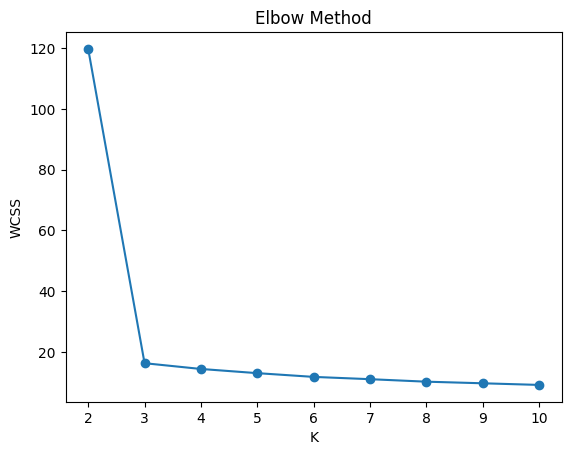

In [57]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss=[]

for k in range(2,11):
    k_means=KMeans(n_clusters=k,random_state=42,n_init=10)
    k_means.fit(x_scaled)
    wcss.append(k_means.inertia_)

plt.plot(range(2,11),wcss,marker='o')
plt.xlabel('K')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()



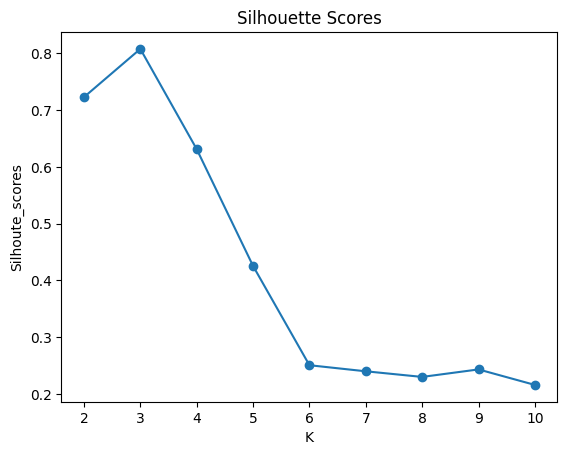

In [58]:
from sklearn.metrics import silhouette_score

silhouette_scores=[]

for k in range(2,11):
    kmean=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=kmean.fit_predict(x_scaled)
    score=silhouette_score(x_scaled,labels)
    silhouette_scores.append(score)


plt.plot(range(2,11),silhouette_scores,marker='o')
plt.xlabel('K')
plt.ylabel('Silhoute_scores')
plt.title('Silhouette Scores')
plt.show()


In [65]:
print('silhouette_scores : ',silhouette_scores)
best_silhoute=max(silhouette_scores)
print('best_silhoute:',best_silhoute)
silhouette_scores.index(best_silhoute)

silhouette_scores :  [0.7227603333978972, 0.8076583740638499, 0.6312493148098199, 0.4256155864833611, 0.25083547576243054, 0.2401428324308814, 0.23023410978335443, 0.24343959555426609, 0.2161516141948716]
best_silhoute: 0.8076583740638499


1

***Final K Mean***

In [60]:
final_model=KMeans(n_clusters=3,n_init=10,random_state=42)
final_model.fit(x_scaled)

cdf['Cluster']=final_model.predict(x_scaled)

In [61]:
cdf

,Age,Annual_Income_Index,Spending_Score,Monthly_Visits,Segment_Reference,Cluster
0,48.5,60.1,65.5,68.8,Regular,2
1,21.4,26.8,25.7,29.0,Budget,0
2,70.0,87.3,88.5,84.5,Premium,1
3,52.1,60.3,58.1,73.8,Regular,2
4,55.3,61.0,60.8,68.5,Regular,2
...,...,...,...,...,...,...
145,47.5,52.8,58.0,67.0,Regular,2
146,70.0,89.5,85.0,90.0,Premium,1
147,18.1,29.1,19.0,33.9,Budget,0
148,57.0,57.1,56.2,59.7,Regular,2


***Cluster Profiling***

In [62]:
cdf.groupby('Cluster')[X.columns].mean()

,Age,Annual_Income_Index,Spending_Score,Monthly_Visits
Cluster,,,,
0,24.132,25.096,19.802,30.332
1,70.000,89.574,86.706,92.088
2,55.594,59.894,55.162,65.724


***Cluster Plotting***

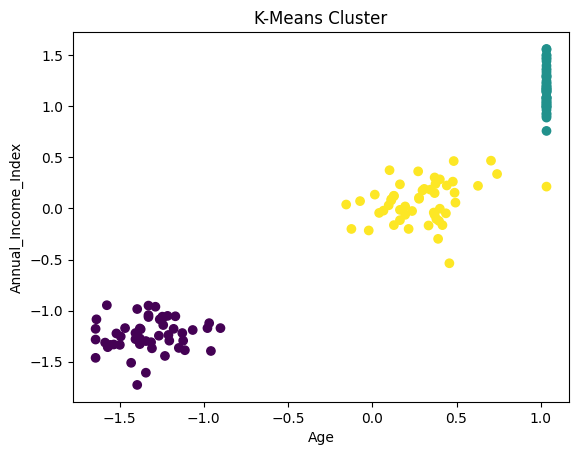

In [ ]:
plt.scatter(x_scaled[:,0],x_scaled[:,1],c=cdf['Cluster'])
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Cluster")
plt.show()

